# Evaluating `TARGET_WAIT`

`TARGET_WAIT = 0.65` is the setpoint of the adaptive trigger threshold in `2_intervention.py`. It is
the only knob that trades the two things a closed-loop session cares about against each other:
firing only on high-confidence brain states (**selectivity**), and not running out of time and firing
blind (**forced pulses**). Raise it and PRIME waits longer for a better moment, which means a higher
threshold, better states, and more trials that time out at `PRIME_MAX_WAIT`. Lower it and the
opposite.

The question this notebook asks is whether the two sessions already recorded can say what other
values of `TARGET_WAIT` would have produced — without running them.

The answer is **partly, and the boundary is sharp**. `prime_predictions.csv` logs the model's
probability at *every* quality-control-passing 10 ms tick, not just the one that fired, so each trial
carries its own within-trial record of what a different threshold would have done. But that record
**stops at the moment the trial triggered**: for any threshold the trial's own trace never reached,
what would have happened next was never observed. Lower thresholds are therefore fully identified
from the data, and higher ones — the selective direction, the interesting one — are only bounded.

Sections 2-4 establish the mechanism and show the controller can be reproduced exactly. Section 5
shows why the obvious empirical approach fails. Sections 6-8 build the within-trial counterfactual
and measure precisely how far it can be pushed. Section 9 is the answer, section 10 is the part
worth acting on.

Both closed-loop sessions are used throughout, side by side: a result that does not replicate across
pilot003 and pilot004 is not a result.

## 1 · Setup

Two inputs per session, both written by the decider itself:

- `trials_intervention.csv` — one row per trial, carrying `search_time`, `qc_failures`, `is_forced`
  and the `threshold` that was in force.
- `prime_predictions.csv` — one row per prediction *attempt*: `probability`, `attempt`,
  `t_since_trial_start`, `qc_failures_so_far`, and whether that attempt `triggered`. Only
  PRIME-guided trials appear (`prime_triplet` and `prime_single_pulse`); `predetermined_single`
  trials never enter `process_periodic`, so they are outside this analysis entirely.

In [1]:
from __future__ import annotations

import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (10, 3.4),
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Chapter-1 palette, reused so conditions keep their colours across notebooks.
COLOR_PREDETERMINED = "#5b8ff9"   # blue
COLOR_PRIME_SINGLE  = "#e8684a"   # orange
COLOR_PRIME_TRIPLET = "#9270ca"   # purple


def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Could not locate the Loop root; set the LOOP_ROOT environment variable.")


LOOP_ROOT = _find_loop_root()

SESSIONS = {
    "pilot003": LOOP_ROOT / "BIDS" / "sub-pilot003" / "ses-prime" / "103" / "prime",
    "pilot004": LOOP_ROOT / "BIDS" / "sub-pilot004" / "ses-prime" / "104" / "prime",
}
GUIDED = ["prime_triplet", "prime_single_pulse"]

print(f"Loop root: {LOOP_ROOT}")
for name, d in SESSIONS.items():
    ok = (d / "trials_intervention.csv").is_file() and (d / "prime_predictions.csv").is_file()
    print(f"  {name}: {'both inputs present' if ok else 'MISSING INPUTS'}  ({d})")

Loop root: D:\Linus\Loop
  pilot003: both inputs present  (D:\Linus\Loop\BIDS\sub-pilot003\ses-prime\103\prime)
  pilot004: both inputs present  (D:\Linus\Loop\BIDS\sub-pilot004\ses-prime\104\prime)


## 2 · The control law, and why its fixed point is the whole story

From `2_intervention.py`. After every PRIME-guided trial, `update_threshold()` runs once:

```python
elapsed = pulse_time - self.search_start_time
active  = max(0.0, elapsed - self.qc_fail_count * PERIODIC_INTERVAL)
self.prediction_threshold = min(max(
    self.prediction_threshold + THRESHOLD_GAIN * (TARGET_WAIT - active),
    THRESHOLD_MIN), THRESHOLD_MAX)
```

Two things follow, and together they determine everything below.

**`active` is search time with the QC-blocked ticks removed.** `process_periodic` fires every
`PERIODIC_INTERVAL` = 10 ms; a tick either passes QC and becomes a prediction attempt, or fails and
increments `qc_fail_count`. Subtracting the failures leaves exactly the time PRIME spent actually
looking at usable data. So `active` is, to within one tick, just the attempt count × 10 ms — which is
what makes the counterfactual in section 6 arithmetic rather than simulation. This is also why "we
already know how the QC went" matters: the QC pattern is read straight off the log rather than
modelled.

**The controller is a pure integrator, so it has one fixed point.** The threshold only stops moving
when `active == TARGET_WAIT` on average. `THRESHOLD_GAIN` and the `[0.50, 0.95]` clamp set how fast
it gets there and where it can be pinned, but the destination is fixed by `TARGET_WAIT` alone.
Choosing `TARGET_WAIT` is therefore *equivalent to* choosing the equilibrium threshold θ\* at which
the mean active wait equals `TARGET_WAIT`:

$$\theta^*(\text{TARGET\_WAIT}) : \quad \mathbb{E}[\,\text{active} \mid \theta^*\,] = \text{TARGET\_WAIT}$$

That reduces the question from "simulate a different session" to "estimate the curve
$\mathbb{E}[\text{active} \mid \theta]$, then invert it" — and the forced rate and selectivity at
that same θ\* say what the choice buys.

In [2]:
# ---------------------------------------------------------------- constants, from 2_intervention.py
THRESHOLD_INIT    = 0.75
THRESHOLD_GAIN    = 0.02     # probability units per second of deviation from TARGET_WAIT
THRESHOLD_MIN     = 0.50
THRESHOLD_MAX     = 0.95
TARGET_WAIT       = 0.65     # s -- the parameter under evaluation
PRIME_MAX_WAIT    = 5.5      # s -- wall clock from trial start to a forced trigger
PERIODIC_INTERVAL = 0.01     # s

print(f"threshold starts at {THRESHOLD_INIT}, clamped to [{THRESHOLD_MIN}, {THRESHOLD_MAX}]")
print(f"gain {THRESHOLD_GAIN}/s  ->  a trial that waits 1 s longer than TARGET_WAIT moves the "
      f"threshold by {THRESHOLD_GAIN:.3f}")
print(f"a forced trial (active up to ~{PRIME_MAX_WAIT - 2.5:.1f} s) moves it by up to "
      f"~{THRESHOLD_GAIN * (PRIME_MAX_WAIT - 2.5 - TARGET_WAIT):.3f} in one step -- the largest "
      f"single update, as the docstring notes")


def load_session(d: Path) -> tuple[pd.DataFrame, dict]:
    '''Per-trial table (PRIME-guided only) plus each trial's probability trace.'''
    IV = pd.read_csv(d / "trials_intervention.csv")
    IV = IV[IV.stage.str.startswith("intervention_block")]
    IV = IV.sort_values(["stage", "trial_in_stage"]).reset_index(drop=True)
    G = IV[IV.condition.isin(GUIDED)].copy().reset_index(drop=True)
    G["is_forced"] = G.is_forced.astype(bool)
    G["active"] = (G.search_time - G.qc_failures * PERIODIC_INTERVAL).clip(lower=0)
    G["trial_order"] = np.arange(len(G))

    P = pd.read_csv(d / "prime_predictions.csv")
    key = ["stage", "trial_in_stage"]
    traces = {k: v.sort_values("attempt").probability.to_numpy()
              for k, v in P[~P.forced].groupby(key)}
    return G, traces


DATA = {name: load_session(d) for name, d in SESSIONS.items()}
for name, (G, traces) in DATA.items():
    print(f"\n{name}: {len(G)} PRIME-guided trials, {len(traces)} with a probability trace, "
          f"{int(G.is_forced.sum())} forced ({100 * G.is_forced.mean():.1f}%)")

threshold starts at 0.75, clamped to [0.5, 0.95]
gain 0.02/s  ->  a trial that waits 1 s longer than TARGET_WAIT moves the threshold by 0.020
a forced trial (active up to ~3.0 s) moves it by up to ~0.047 in one step -- the largest single update, as the docstring notes

pilot003: 720 PRIME-guided trials, 719 with a probability trace, 50 forced (6.9%)

pilot004: 720 PRIME-guided trials, 720 with a probability trace, 78 forced (10.8%)


## 3 · Validation — reproducing the session's own threshold trajectory

Before using the control law to explore values it never ran at, it has to reproduce the one it did
run at. Replaying `update_threshold()` over each session's trials, starting from `THRESHOLD_INIT`
and feeding it each trial's own recorded `search_time` and `qc_failures`, should regenerate the
`threshold` column the decider logged — every trial, to floating-point precision.

If that matches, the arithmetic here is the arithmetic that ran, and only the *inputs* to it are in
question from section 6 on.

In [3]:
def replay_controller(G: pd.DataFrame, target_wait: float = TARGET_WAIT,
                      actives: np.ndarray | None = None) -> np.ndarray:
    '''Threshold in force at each trial, given the active wait each trial produced.'''
    a = G.active.to_numpy() if actives is None else np.asarray(actives)
    th, out = THRESHOLD_INIT, np.empty(len(a))
    for i in range(len(a)):
        out[i] = th
        th = min(max(th + THRESHOLD_GAIN * (target_wait - a[i]), THRESHOLD_MIN), THRESHOLD_MAX)
    return out


rows = []
for name, (G, _) in DATA.items():
    sim = replay_controller(G)
    err = np.abs(sim - G.threshold.to_numpy())
    rows.append({"session": name, "n_trials": len(G), "max_abs_err": err.max(),
                 "mean_abs_err": err.mean(),
                 "logged_start": G.threshold.iloc[0], "logged_end": G.threshold.iloc[-1],
                 "logged_min": G.threshold.min(), "logged_max": G.threshold.max(),
                 "pct_at_floor": 100 * (G.threshold <= THRESHOLD_MIN + 1e-9).mean()})
val = pd.DataFrame(rows).set_index("session")
display(val)
print("max |simulated - logged| is at float-noise level -> the controller is reproduced exactly.")

,n_trials,max_abs_err,mean_abs_err,logged_start,logged_end,logged_min,logged_max,pct_at_floor
session,,,,,,,,
pilot003,720,2.220446e-16,1.128727e-16,0.75,0.539004,0.5,0.833512,0.416667
pilot004,720,3.219647e-15,1.598875e-15,0.75,0.563584,0.5,0.808600,0.277778


max |simulated - logged| is at float-noise level -> the controller is reproduced exactly.


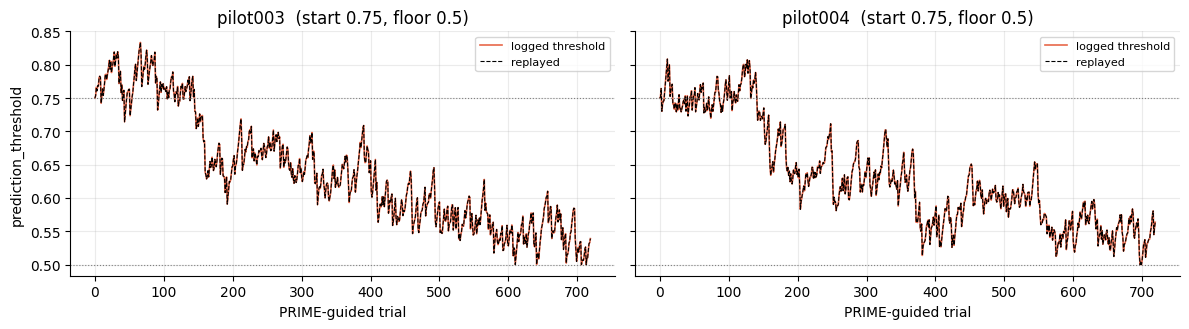

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (name, (G, _)) in zip(axes, DATA.items()):
    ax.plot(G.trial_order, G.threshold, color=COLOR_PRIME_SINGLE, lw=1.2, label="logged threshold")
    ax.plot(G.trial_order, replay_controller(G), color="k", lw=0.8, ls="--", label="replayed")
    ax.axhline(THRESHOLD_MIN, color="grey", lw=0.8, ls=":")
    ax.axhline(THRESHOLD_INIT, color="grey", lw=0.8, ls=":")
    ax.set_title(f"{name}  (start {THRESHOLD_INIT}, floor {THRESHOLD_MIN})")
    ax.set_xlabel("PRIME-guided trial")
    ax.legend(fontsize=8)
axes[0].set_ylabel("prediction_threshold")
fig.tight_layout()
plt.show()

## 4 · Where the session actually sat

Worth establishing before asking about other setpoints: what did `TARGET_WAIT = 0.65` actually
deliver? The controller drives the *mean* active wait toward the setpoint, so comparing the two says
how close to equilibrium the session got, and the residual tells us which way it was still moving.

In [5]:
rows = []
for name, (G, _) in DATA.items():
    mean_active = G.active.mean()
    rows.append({
        "session": name,
        "mean active (s)": round(mean_active, 4),
        "median active (s)": round(G.active.median(), 4),
        "TARGET_WAIT": TARGET_WAIT,
        "residual (s)": round(TARGET_WAIT - mean_active, 4),
        "drift/trial": round(THRESHOLD_GAIN * (TARGET_WAIT - mean_active), 6),
        "drift over session": round(THRESHOLD_GAIN * (TARGET_WAIT - mean_active) * len(G), 4),
        "observed threshold change": round(G.threshold.iloc[-1] - G.threshold.iloc[0], 4),
        "forced %": round(100 * G.is_forced.mean(), 2),
        "mean threshold": round(G.threshold.mean(), 4),
    })
display(pd.DataFrame(rows).set_index("session"))

print("The mean active wait lands within ~2% of TARGET_WAIT in both sessions, so the loop was")
print("essentially at its fixed point -- but the small negative residual is exactly the observed")
print("threshold decline, i.e. it was still drifting down from THRESHOLD_INIT=0.75 and had not")
print("finished converging after 720 trials. The gain is simply small relative to the session.")

,mean active (s),median active (s),TARGET_WAIT,residual (s),drift/trial,drift over session,observed threshold change,forced %,mean threshold
session,,,,,,,,,
pilot003,0.6664,0.3800,0.65,-0.0164,-0.000327,-0.2358,-0.2110,6.94,0.6394
pilot004,0.6667,0.4002,0.65,-0.0167,-0.000334,-0.2402,-0.1864,10.83,0.6313


The mean active wait lands within ~2% of TARGET_WAIT in both sessions, so the loop was
essentially at its fixed point -- but the small negative residual is exactly the observed
threshold decline, i.e. it was still drifting down from THRESHOLD_INIT=0.75 and had not
finished converging after 720 trials. The gain is simply small relative to the session.


## 5 · Why the obvious approach does not work

The tempting shortcut: the threshold *already* swept a wide range within each session (roughly
0.50-0.83), so just bin trials by the threshold that was in force and read off the wait time and
forced rate in each bin. No counterfactual needed.

This fails, and it is worth showing why rather than discovering it later. The threshold is not
varied independently — it is driven by the trial history, and it descends monotonically from
`THRESHOLD_INIT` as the session runs. So "threshold" and "time into the session" are nearly the same
variable, and any drift in the subject (drowsiness, impedance, alpha power) loads onto the estimate.

In [6]:
BINS = np.arange(0.50, 0.875, 0.025)
pooled = pd.concat([G.assign(session=n) for n, (G, _) in DATA.items()], ignore_index=True)
pooled["th_bin"] = pd.cut(pooled.threshold, BINS)

binned = pooled.groupby("th_bin", observed=True).agg(
    n=("threshold", "size"), theta=("threshold", "mean"),
    mean_active=("active", "mean"), forced_pct=("is_forced", lambda s: 100 * s.mean()),
).round(3)
display(binned[binned.n >= 20])

print("confound: correlation of the threshold in force with position in the session")
for name, (G, _) in DATA.items():
    print(f"  {name}: corr(threshold, trial_order) = {G.threshold.corr(G.trial_order):+.3f}"
          f"   |   corr(active, threshold) = {G.active.corr(G.threshold):+.3f}")
print()
print("The threshold is ~0.9 collinear with time-in-session, while its correlation with the thing")
print("it supposedly controls is ~0.09. Binning by it measures the session clock, not the threshold.")
print("The non-monotonic mean_active column above is that noise. A within-trial design is needed.")

,n,theta,mean_active,forced_pct
th_bin,,,,
"(0.5, 0.525]",47,0.516,0.428,2.128
"(0.525, 0.55]",159,0.539,0.511,3.774
"(0.55, 0.575]",187,0.563,0.631,8.021
"(0.575, 0.6]",176,0.588,0.703,10.795
"(0.6, 0.625]",180,0.613,0.678,12.222
"(0.625, 0.65]",173,0.638,0.686,5.202
"(0.65, 0.675]",112,0.661,0.778,8.929
"(0.675, 0.7]",72,0.686,0.739,13.889
"(0.7, 0.725]",38,0.712,0.969,28.947


confound: correlation of the threshold in force with position in the session
  pilot003: corr(threshold, trial_order) = -0.919   |   corr(active, threshold) = +0.090
  pilot004: corr(threshold, trial_order) = -0.872   |   corr(active, threshold) = +0.087

The threshold is ~0.9 collinear with time-in-session, while its correlation with the thing
it supposedly controls is ~0.09. Binning by it measures the session clock, not the threshold.
The non-monotonic mean_active column above is that noise. A within-trial design is needed.


## 6 · The within-trial counterfactual

`prime_predictions.csv` records the probability at every QC-passing tick of every trial, so each
trial carries its own answer to "when would a different threshold have fired?" — the first attempt
$k$ at which $p_k \ge \theta$. That is a *within-trial* comparison: the same trial, the same brain
data, a different cutoff. The session-clock confound of section 5 cannot enter.

The active wait at that counterfactual trigger needs no modelling either. Since each logged attempt
is one QC-passing tick, triggering at attempt $k$ instead of the observed attempt $n$ simply removes
$(n - k)$ ticks of active search:

$$\text{active}(k) = \text{active}_\text{observed} - (n-k)\times\texttt{PERIODIC\_INTERVAL}$$

Anchoring on the observed value rather than computing from `search_start_time` makes the trigger
offset and the pre-search delay cancel, so nothing has to be assumed about either.

**The assumption that does matter** is that a trial's recorded probability trace is unchanged by
when the pulse eventually lands. Within a trial that is safe — the trace up to the trigger is already
history. Across trials it is not strictly true: firing at a different moment changes the next trial's
pre-stimulus state, and PRIME is finetuning as it goes. This is a first-order approximation, and it
is the reason section 9 reports a direction and a magnitude rather than a precise operating point.

In [7]:
def crossing(trace: np.ndarray, theta: float) -> int | None:
    '''1-based index of the first attempt at or above theta, or None.'''
    hit = np.flatnonzero(trace >= theta)
    return int(hit[0]) + 1 if hit.size else None


# Sanity check: replaying each trial at its OWN logged threshold must land on its own logged attempt.
for name, (G, traces) in DATA.items():
    agree = tot = 0
    for r in G.itertuples():
        tr = traces.get((r.stage, r.trial_in_stage))
        if tr is None or r.is_forced:
            continue
        k = crossing(tr, r.threshold)
        tot += 1
        agree += (k == len(tr))
    print(f"{name}: replaying at each trial's own threshold reproduces the observed trigger attempt "
          f"for {agree}/{tot} non-forced trials ({100 * agree / tot:.1f}%)")
print()
print("Not 100% by construction -- the threshold moves between the log row and the trigger decision")
print("in a handful of trials -- but close enough that the trace/threshold alignment is sound.")

pilot003: replaying at each trial's own threshold reproduces the observed trigger attempt for 670/670 non-forced trials (100.0%)
pilot004: replaying at each trial's own threshold reproduces the observed trigger attempt for 640/642 non-forced trials (99.7%)

Not 100% by construction -- the threshold moves between the log row and the trigger decision
in a handful of trials -- but close enough that the trace/threshold alignment is sound.


## 7 · The identification boundary

Here is the limit of what the data can answer. A trial's trace ends when it fired. If the highest
probability anywhere in that trace is below θ, the trial would *not* have fired at θ within the
window we observed — and what it did next was never recorded. Those trials are **right-censored** at
θ.

Two cases are not censored and carry the analysis:

- Any θ at or below a trial's trace maximum: the first crossing is directly observed.
- **Forced trials**: they searched the full `PRIME_MAX_WAIT` without ever crossing, so their trace is
  complete. At any θ above their maximum they would simply have been forced again — known, not
  guessed.

So censoring is confined to non-forced trials at θ above their own trace maximum, and it grows
sharply with θ, because non-forced trials are short by construction (they stopped as soon as they
crossed).

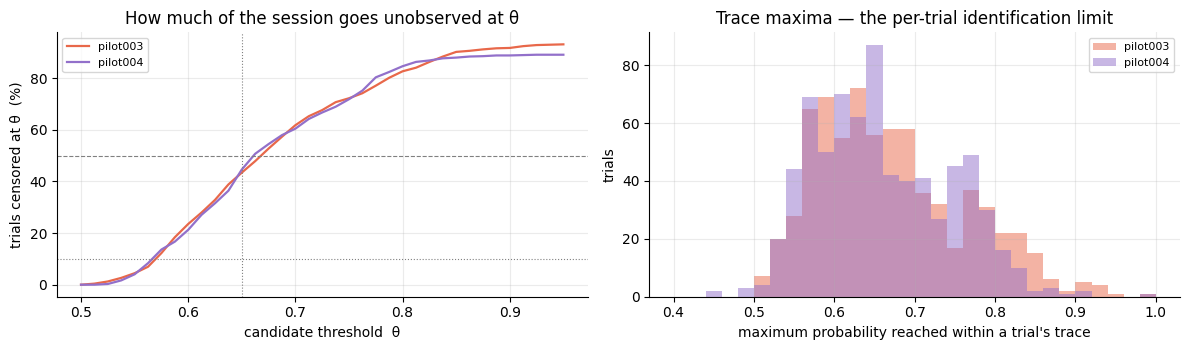

,pilot003,pilot004
θ at 10% censored,0.570,0.566
θ at 25% censored,0.604,0.608
θ at 50% censored,0.668,0.661


Below roughly θ = 0.55 the counterfactual is essentially complete; by θ = 0.65 half the
session is unobserved. Everything in section 9 has to be read against this curve.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
thetas = np.round(np.arange(0.50, 0.951, 0.0125), 4)

cens_curves = {}
for name, (G, traces) in DATA.items():
    tmax = {k: float(v.max()) for k, v in traces.items()}
    forced = {(r.stage, r.trial_in_stage): bool(r.is_forced) for r in G.itertuples()}
    keys = [k for k in traces if k in forced]
    frac = [100 * np.mean([(tmax[k] < th) and not forced[k] for k in keys]) for th in thetas]
    cens_curves[name] = np.array(frac)
    axes[0].plot(thetas, frac, lw=1.6,
                 color=COLOR_PRIME_SINGLE if name == "pilot003" else COLOR_PRIME_TRIPLET, label=name)
    axes[1].hist([tmax[k] for k in keys], bins=np.arange(0.40, 1.01, 0.02), alpha=0.5,
                 color=COLOR_PRIME_SINGLE if name == "pilot003" else COLOR_PRIME_TRIPLET, label=name)

axes[0].axvline(TARGET_WAIT, color="grey", lw=0.8, ls=":")
for lim, style in [(10, ":"), (50, "--")]:
    axes[0].axhline(lim, color="grey", lw=0.8, ls=style)
axes[0].set_xlabel("candidate threshold  θ")
axes[0].set_ylabel("trials censored at θ  (%)")
axes[0].set_title("How much of the session goes unobserved at θ")
axes[0].legend(fontsize=8)

axes[1].set_xlabel("maximum probability reached within a trial's trace")
axes[1].set_ylabel("trials")
axes[1].set_title("Trace maxima — the per-trial identification limit")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

summary = pd.DataFrame({name: np.interp([10, 25, 50], c, thetas) for name, c in cens_curves.items()},
                       index=["θ at 10% censored", "θ at 25% censored", "θ at 50% censored"]).round(3)
display(summary)
print("Below roughly θ = 0.55 the counterfactual is essentially complete; by θ = 0.65 half the")
print("session is unobserved. Everything in section 9 has to be read against this curve.")

## 8 · The threshold sweep, with bounds

For each candidate θ, every trial falls into one of three cases, and only the third needs a
judgement call:

| case | active wait | forced? |
|---|---|---|
| trace crosses θ at attempt $k$ | $\text{active}_\text{obs} - (n-k)\,\delta t$ | no |
| forced trial, never crosses θ | its observed active time | yes |
| **censored** (non-forced, never crosses) | **unknown** | **unknown** |

Rather than pick one answer for the censored trials, both extremes are carried through:

- **Optimistic** — the trial would have crossed at the very next attempt. A lower bound on wait, a
  lower bound on the forced rate.
- **Pessimistic** — it would never have crossed and would have been forced.

The truth is between them, and the gap between the two curves *is* the uncertainty the data cannot
remove. A Kaplan-Meier estimate is shown alongside as a conventional point estimate: it treats the
censoring as non-informative, which is not quite true here (trials with long traces are the ones
that were struggling), so it should be read as a reasonable interior value rather than the answer.

In [9]:
def km_restricted_mean(time, event, horizon):
    '''Kaplan-Meier restricted mean survival time up to `horizon`.'''
    time, event = np.asarray(time, float), np.asarray(event, int)
    order = np.argsort(time, kind="mergesort")
    t, e = time[order], event[order]
    S, prev, area = 1.0, 0.0, 0.0
    for ti in np.unique(t[e == 1]):
        if ti > horizon:
            break
        at_risk = int((t >= ti).sum())
        d = int(((t == ti) & (e == 1)).sum())
        if at_risk == 0:
            break
        area += S * (ti - prev)
        S *= 1 - d / at_risk
        prev = ti
    return area + S * (horizon - prev)


def sweep_session(G, traces, thetas):
    forced_active = float(G.loc[G.is_forced, "active"].median())
    horizon = float(G.active.max())
    recs = []
    for r in G.itertuples():
        tr = traces.get((r.stage, r.trial_in_stage))
        if tr is not None:
            recs.append((tr, r.active, bool(r.is_forced)))
    out = []
    for th in thetas:
        a_opt, a_pes, km_t, km_e, ps = [], [], [], [], []
        f_opt = f_pes = ncens = 0
        for tr, a_obs, was_forced in recs:
            k = crossing(tr, th)
            if k is not None:
                a = max(a_obs - (len(tr) - k) * PERIODIC_INTERVAL, 0.0)
                a_opt.append(a); a_pes.append(a); ps.append(float(tr[k - 1]))
                km_t.append(a); km_e.append(1)
            elif was_forced:
                a_opt.append(a_obs); a_pes.append(a_obs); f_opt += 1; f_pes += 1
                km_t.append(a_obs); km_e.append(1)
            else:
                ncens += 1
                a_opt.append(a_obs + PERIODIC_INTERVAL); ps.append(th)
                a_pes.append(forced_active); f_pes += 1
                km_t.append(a_obs); km_e.append(0)
        n = len(recs)
        out.append({"theta": th, "n_censored": ncens, "pct_censored": 100 * ncens / n,
                    "E_active_opt": np.mean(a_opt), "E_active_pes": np.mean(a_pes),
                    "E_active_km": km_restricted_mean(km_t, km_e, horizon),
                    "forced_pct_opt": 100 * f_opt / n, "forced_pct_pes": 100 * f_pes / n,
                    "mean_p_trigger": np.mean(ps) if ps else np.nan})
    return pd.DataFrame(out)


THETAS = np.round(np.arange(0.50, 0.8251, 0.0125), 4)
SWEEP = {name: sweep_session(G, traces, THETAS) for name, (G, traces) in DATA.items()}

for name, sw in SWEEP.items():
    print(f"--- {name} ---")
    show = sw[np.isclose(sw.theta % 0.05, 0) | np.isclose(sw.theta % 0.05, 0.05)]
    display(show.round(3).set_index("theta"))

--- pilot003 ---


,n_censored,pct_censored,E_active_opt,E_active_pes,E_active_km,forced_pct_opt,forced_pct_pes,mean_p_trigger
theta,,,,,,,,
0.50,0,0.000,0.091,0.091,0.091,0.000,0.000,0.561
0.55,32,4.451,0.215,0.329,0.240,0.834,5.285,0.600
0.60,169,23.505,0.358,0.930,0.605,2.782,26.287,0.634
0.65,312,43.394,0.487,1.544,1.036,4.590,47.983,0.671
0.70,444,61.752,0.563,2.058,1.589,6.120,67.872,0.712
0.75,519,72.184,0.618,2.361,1.868,6.120,78.303,0.758
0.80,594,82.615,0.669,2.665,2.247,6.537,89.152,0.805


--- pilot004 ---


,n_censored,pct_censored,E_active_opt,E_active_pes,E_active_km,forced_pct_opt,forced_pct_pes,mean_p_trigger
theta,,,,,,,,
0.50,0,0.000,0.122,0.122,0.122,0.694,0.694,0.562
0.55,29,4.028,0.262,0.325,0.282,2.361,6.389,0.598
0.60,153,21.250,0.416,0.733,0.587,5.417,26.667,0.635
0.65,321,44.583,0.522,1.174,1.028,7.361,51.944,0.672
0.70,435,60.417,0.569,1.439,1.411,8.056,68.472,0.714
0.75,517,71.806,0.643,1.685,1.687,9.444,81.250,0.756
0.80,609,84.583,0.672,1.893,2.124,10.556,95.139,0.802


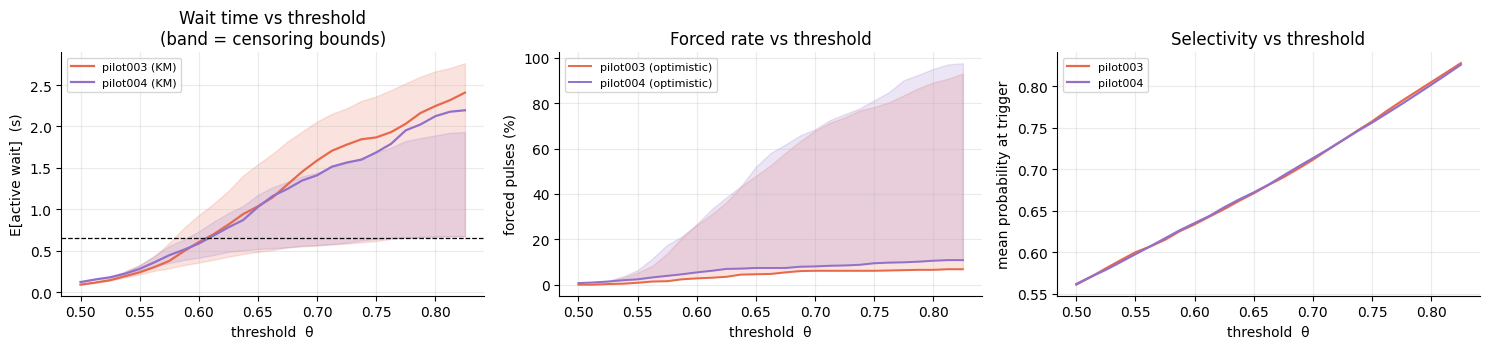

The dashed line in the left panel is TARGET_WAIT: where a curve crosses it is the
equilibrium threshold for that setpoint, which is what section 9 inverts.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for name, sw in SWEEP.items():
    c = COLOR_PRIME_SINGLE if name == "pilot003" else COLOR_PRIME_TRIPLET
    axes[0].fill_between(sw.theta, sw.E_active_opt, sw.E_active_pes, color=c, alpha=0.18)
    axes[0].plot(sw.theta, sw.E_active_km, color=c, lw=1.6, label=f"{name} (KM)")
    axes[1].fill_between(sw.theta, sw.forced_pct_opt, sw.forced_pct_pes, color=c, alpha=0.18)
    axes[1].plot(sw.theta, sw.forced_pct_opt, color=c, lw=1.4, label=f"{name} (optimistic)")
    axes[2].plot(sw.theta, sw.mean_p_trigger, color=c, lw=1.6, label=name)

axes[0].axhline(TARGET_WAIT, color="k", lw=0.9, ls="--")
axes[0].set_ylabel("E[active wait]  (s)"); axes[0].set_title("Wait time vs threshold\n(band = censoring bounds)")
axes[1].set_ylabel("forced pulses (%)"); axes[1].set_title("Forced rate vs threshold")
axes[2].set_ylabel("mean probability at trigger"); axes[2].set_title("Selectivity vs threshold")
for ax in axes:
    ax.set_xlabel("threshold  θ")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("The dashed line in the left panel is TARGET_WAIT: where a curve crosses it is the")
print("equilibrium threshold for that setpoint, which is what section 9 inverts.")

## 9 · What different `TARGET_WAIT` values would have bought

Inverting $\mathbb{E}[\text{active} \mid \theta]$ at each candidate setpoint gives the equilibrium
threshold θ\*, and reading the other two curves at that θ\* gives the forced rate and the selectivity
that come with it. Doing this on the optimistic and pessimistic curves separately brackets the
answer.

Two sanity conditions on the result: at the real `TARGET_WAIT = 0.65` the bracket should contain the
session's own mean threshold and its own forced rate, and the two sessions should agree.

In [11]:
def invert(sw, tw, ecol, fcol):
    e = sw[ecol].to_numpy()
    if tw < e.min() or tw > e.max():
        return None
    th_star = float(np.interp(tw, e, sw.theta.to_numpy()))
    return {
        "theta*": round(th_star, 3),
        "forced %": round(float(np.interp(th_star, sw.theta, sw[fcol])), 1),
        "mean p@trigger": round(float(np.interp(th_star, sw.theta, sw.mean_p_trigger)), 3),
        "% censored there": round(float(np.interp(th_star, sw.theta, sw.pct_censored)), 1),
    }


def at_theta(sw, th_star):
    '''Read the forced-rate bracket and selectivity off the sweep at a given threshold.'''
    return {
        "forced % (lo)": round(float(np.interp(th_star, sw.theta, sw.forced_pct_opt)), 1),
        "forced % (hi)": round(float(np.interp(th_star, sw.theta, sw.forced_pct_pes)), 1),
        "p@trigger": round(float(np.interp(th_star, sw.theta, sw.mean_p_trigger)), 3),
        "censored %": round(float(np.interp(th_star, sw.theta, sw.pct_censored)), 1),
    }


CANDIDATES = [0.30, 0.40, 0.50, 0.65, 0.80, 1.00, 1.25]
rows = []
for name, sw in SWEEP.items():
    for tw in CANDIDATES:
        lo = invert(sw, tw, "E_active_opt", "forced_pct_opt")
        mid = invert(sw, tw, "E_active_km", "forced_pct_opt")
        hi = invert(sw, tw, "E_active_pes", "forced_pct_pes")
        row = {"session": name, "TARGET_WAIT": tw,
               "θ* (KM)": mid["theta*"] if mid else None,
               "θ* range": (f"{min(hi['theta*'], lo['theta*']):.3f}-{max(hi['theta*'], lo['theta*']):.3f}"
                            if (lo and hi) else None)}
        row.update(at_theta(sw, mid["theta*"]) if mid else
                   {"forced % (lo)": None, "forced % (hi)": None, "p@trigger": None, "censored %": None})
        rows.append(row)
res = pd.DataFrame(rows).set_index(["session", "TARGET_WAIT"])
display(res)
print("θ* (KM) is the central estimate; 'θ* range' is the optimistic-pessimistic bracket. The")
print("forced-rate columns are the bracket read at the central θ*, since the censoring uncertainty")
print("does not go away once the threshold is pinned down.")
print()

print("cross-check at the real setpoint (TARGET_WAIT = 0.65) -- does the method recover the session?")
for name, (G, _) in DATA.items():
    sw = SWEEP[name]
    lo = invert(sw, 0.65, "E_active_opt", "forced_pct_opt")
    mid = invert(sw, 0.65, "E_active_km", "forced_pct_opt")
    hi = invert(sw, 0.65, "E_active_pes", "forced_pct_pes")
    a, b = sorted([lo["theta*"], hi["theta*"]])
    obs_th, obs_f = G.threshold.mean(), 100 * G.is_forced.mean()
    at = at_theta(sw, mid["theta*"])
    print(f"  {name}")
    print(f"    θ*  : central {mid['theta*']:.3f}, bracket [{a:.3f}, {b:.3f}]   "
          f"session's own mean threshold {obs_th:.3f}  -> "
          f"{'inside the bracket' if a <= obs_th <= b else 'OUTSIDE -- method disagrees with reality'}")
    print(f"    forced: bracket [{at['forced % (lo)']:.1f}%, {at['forced % (hi)']:.1f}%]   "
          f"observed {obs_f:.1f}%  -> "
          f"{'inside' if at['forced % (lo)'] <= obs_f <= at['forced % (hi)'] else 'OUTSIDE'}")

θ* (KM)     θ* range  forced % (lo)  forced % (hi)  p@trigger  censored %
session  TARGET_WAIT                                                                           
pilot003 0.30           0.562  0.545-0.579            1.4            8.2      0.607         6.9
         0.40           0.577  0.559-0.615            1.7           14.9      0.617        13.2
         0.50           0.588  0.568-0.657            2.4           20.9      0.626        18.6
         0.65           0.606  0.579-0.769            2.9           28.6      0.638        25.6
         0.80           0.623         None            3.4           35.5      0.651        32.0
         1.00           0.645         None            4.5           46.1      0.668        41.6
         1.25           0.671         None            5.2           56.4      0.687        51.2
pilot004 0.30           0.553  0.546-0.559            2.6            7.6      0.600         5.1
         0.40           0.568  0.558-0.592            3.5           14.2      0.611        10.7
         0.50           0.585  0.569-0.633            4.4           20.5      0.625        16.1
         0.65           0.608  0.589-0.757            5.9           30.8      0.641        25.0
         0.80           0.628         None            7.0           39.7      0.656        32.7
         1.00           0.648         None            7.3           50.6      0.671        43.3
         1.25           0.675         None            7.4           61.8      0.692        54.4

θ* (KM) is the central estimate; 'θ* range' is the optimistic-pessimistic bracket. The
forced-rate columns are the bracket read at the central θ*, since the censoring uncertainty
does not go away once the threshold is pinned down.

cross-check at the real setpoint (TARGET_WAIT = 0.65) -- does the method recover the session?
  pilot003
    θ*  : central 0.606, bracket [0.579, 0.769]   session's own mean threshold 0.639  -> inside the bracket
    forced: bracket [2.9%, 28.6%]   observed 6.9%  -> inside
  pilot004
    θ*  : central 0.608, bracket [0.589, 0.757]   session's own mean threshold 0.631  -> inside the bracket
    forced: bracket [5.9%, 30.8%]   observed 10.8%  -> inside


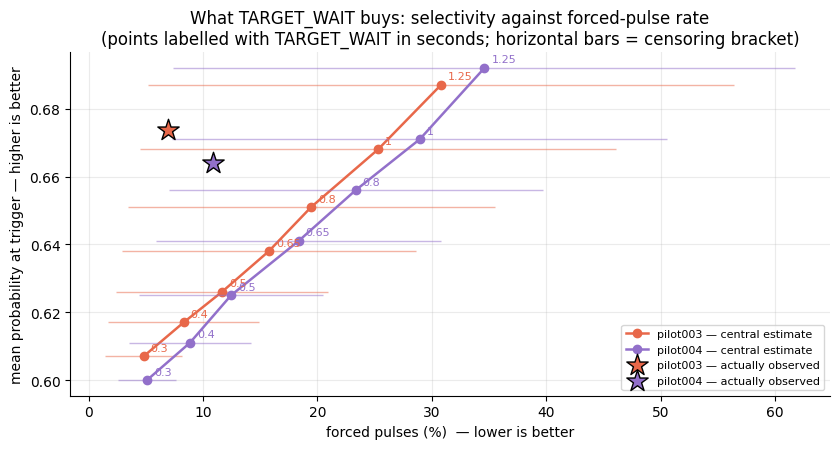

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for name, sw in SWEEP.items():
    c = COLOR_PRIME_SINGLE if name == "pilot003" else COLOR_PRIME_TRIPLET
    xs, ys, xlo, xhi, labels = [], [], [], [], []
    for tw in CANDIDATES:
        mid = invert(sw, tw, "E_active_km", "forced_pct_opt")
        if mid is None:
            continue
        at = at_theta(sw, mid["theta*"])
        xs.append((at["forced % (lo)"] + at["forced % (hi)"]) / 2)
        xlo.append(at["forced % (lo)"]); xhi.append(at["forced % (hi)"])
        ys.append(at["p@trigger"]); labels.append(tw)
    ax.plot(xs, ys, "o-", color=c, lw=1.8, label=f"{name} — central estimate")
    ax.hlines(ys, xlo, xhi, color=c, lw=1.0, alpha=0.5)
    for x, y, tw in zip(xs, ys, labels):
        ax.annotate(f"{tw:g}", (x, y), textcoords="offset points", xytext=(5, 4), fontsize=8, color=c)

for name, (G, _) in DATA.items():
    c = COLOR_PRIME_SINGLE if name == "pilot003" else COLOR_PRIME_TRIPLET
    nf = G[~G.is_forced]
    ax.scatter([100 * G.is_forced.mean()], [nf.prediction_probability.mean()],
               marker="*", s=260, color=c, edgecolor="k", zorder=6,
               label=f"{name} — actually observed")

ax.set_xlabel("forced pulses (%)  — lower is better")
ax.set_ylabel("mean probability at trigger — higher is better")
ax.set_title("What TARGET_WAIT buys: selectivity against forced-pulse rate\n"
             "(points labelled with TARGET_WAIT in seconds; horizontal bars = censoring bracket)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

## 10 · What this does and does not establish

**Established, and robust.** The controller is reproduced exactly (section 3), and both sessions ran
within ~2% of their setpoint — `TARGET_WAIT = 0.65` was very nearly achieved, not merely aimed at.
The threshold's slow decline across both sessions is fully accounted for by the small negative
residual, so nothing anomalous was happening: the loop was converging from `THRESHOLD_INIT = 0.75`
and simply had not arrived after 720 trials. If a future session should reach equilibrium sooner,
the parameter to change is `THRESHOLD_GAIN` or `THRESHOLD_INIT`, not `TARGET_WAIT`.

**The most useful finding, and it is not the one the question anticipated: `TARGET_WAIT` is a weak
lever.** Because $\mathbb{E}[\text{active} \mid \theta]$ rises steeply with θ — roughly 7 seconds of
wait per unit of threshold — a large change in the setpoint buys only a small change in the
equilibrium threshold. Sweeping `TARGET_WAIT` from 0.30 s to 1.25 s, a factor of four, moves θ\* only
from about 0.56 to 0.67, and moves the mean probability at trigger from about 0.61 to 0.69. Both
sessions agree on this closely (θ\*(0.65) = 0.606 and 0.608). So `TARGET_WAIT` mostly does not
control selectivity; it controls how much time is spent, and therefore how often the trial runs out
of it. If the goal is to fire on better states, raising `TARGET_WAIT` is an inefficient way to get
there — `THRESHOLD_INIT`, `THRESHOLD_MIN`, or a better predictor act on selectivity far more
directly.

**Established, with bounds: lowering it looks safe and mildly cheap.** Low setpoints imply low
thresholds, which is exactly where the traces are complete — at `TARGET_WAIT` = 0.30-0.40 only 5-13%
of trials are censored. There the forced rate brackets at 1.4-8.2% (pilot003) and 2.6-7.6%
(pilot004), against 6.9% and 10.8% actually observed, so a reduction is likely though not certain at
the pessimistic edge. The cost is real but small: roughly 0.06 in mean trigger probability.

**Not established: raising it.** This is the direction of interest and the one the data cannot
resolve. By the θ that `TARGET_WAIT` = 0.65 implies, a quarter of each session is censored, and at
0.80 the forced-rate bracket spans 3.4-35.5% — the difference between a minor cost and an unusable
session. No amount of reanalysis narrows that; the information was never recorded.

**A caveat on the central estimate.** The Kaplan-Meier θ\* at the real setpoint comes out at
0.606-0.608 against session mean thresholds of 0.639 and 0.631. It sits inside the bracket and close
to the truth, but consistently a little low — censoring here is mildly informative (the trials with
long traces are the ones that were struggling), which biases KM toward pessimism. Read the central
column as a good estimate with a known lean, not as a point answer.

**The closed-loop caveat, applying to all of the above.** Every counterfactual here holds each
trial's probability trace fixed. Firing at a different moment would change the following trial's
pre-stimulus state and the predictor's own finetuning, so these curves describe the immediate
mechanical consequence of a threshold change, not the settled behaviour of a session actually run
that way. Treat the numbers as a direction and an order of magnitude.

**The cheap fix, and it is genuinely cheap.** The censoring exists only because
`process_periodic` stops logging once a trial triggers. Continuing to log `probability` for the rest
of the `PRIME_MAX_WAIT` window — without acting on it — would make every trial's trace complete and
turn this entire analysis from bounded to exact, for any candidate threshold, at the cost of some
rows in a CSV. Worth doing before the next pilot if `TARGET_WAIT` is a parameter anyone intends to
tune on evidence.

In [13]:
print("Summary — the trade, relative to each session as it actually ran:\n")
for name, sw in SWEEP.items():
    G = DATA[name][0]
    obs_forced = 100 * G.is_forced.mean()
    obs_p = G.loc[~G.is_forced, "prediction_probability"].mean()
    print(f"{name}   observed: forced {obs_forced:.1f}%, mean p@trigger {obs_p:.3f}, "
          f"mean threshold {G.threshold.mean():.3f}")
    for tw in [0.30, 0.40, 0.50, 0.65, 0.80]:
        mid = invert(sw, tw, "E_active_km", "forced_pct_opt")
        if mid is None:
            print(f"    TARGET_WAIT={tw:.2f}  -> outside the identifiable range")
            continue
        at = at_theta(sw, mid["theta*"])
        flag = "" if at["censored %"] < 25 else "   <-- heavily censored, indicative only"
        print(f"    TARGET_WAIT={tw:.2f}  -> θ* {mid['theta*']:.3f}, "
              f"forced {at['forced % (lo)']:.1f}-{at['forced % (hi)']:.1f}%, "
              f"p@trigger {at['p@trigger']:.3f}{flag}")
    print()

Summary — the trade, relative to each session as it actually ran:

pilot003   observed: forced 6.9%, mean p@trigger 0.674, mean threshold 0.639
    TARGET_WAIT=0.30  -> θ* 0.562, forced 1.4-8.2%, p@trigger 0.607
    TARGET_WAIT=0.40  -> θ* 0.577, forced 1.7-14.9%, p@trigger 0.617
    TARGET_WAIT=0.50  -> θ* 0.588, forced 2.4-20.9%, p@trigger 0.626
    TARGET_WAIT=0.65  -> θ* 0.606, forced 2.9-28.6%, p@trigger 0.638   <-- heavily censored, indicative only
    TARGET_WAIT=0.80  -> θ* 0.623, forced 3.4-35.5%, p@trigger 0.651   <-- heavily censored, indicative only

pilot004   observed: forced 10.8%, mean p@trigger 0.664, mean threshold 0.631
    TARGET_WAIT=0.30  -> θ* 0.553, forced 2.6-7.6%, p@trigger 0.600
    TARGET_WAIT=0.40  -> θ* 0.568, forced 3.5-14.2%, p@trigger 0.611
    TARGET_WAIT=0.50  -> θ* 0.585, forced 4.4-20.5%, p@trigger 0.625
    TARGET_WAIT=0.65  -> θ* 0.608, forced 5.9-30.8%, p@trigger 0.641   <-- heavily censored, indicative only
    TARGET_WAIT=0.80  -> θ* 0.628, for